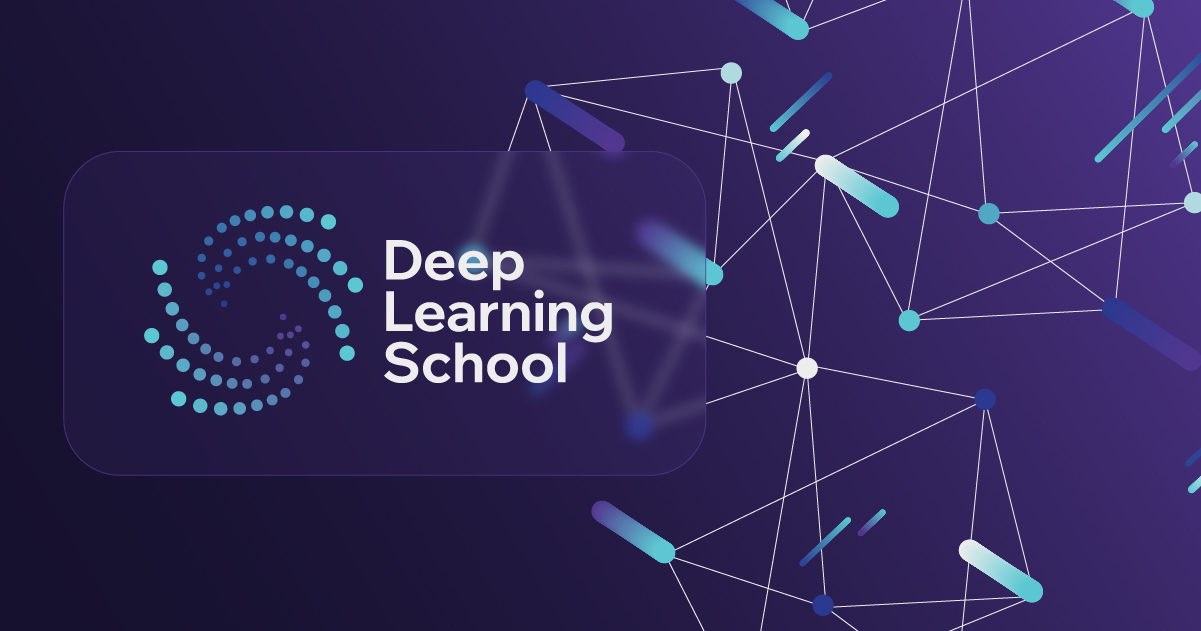

<h3 style="text-align: center;"><b>Школа глубокого обучения ФПМИ МФТИ</b></h3>

<h1 style="text-align: center;"><b>Домашнее задание. Библиотека sklearn и классификация с помощью KNN</b></h1>

## Описание домашнего задания

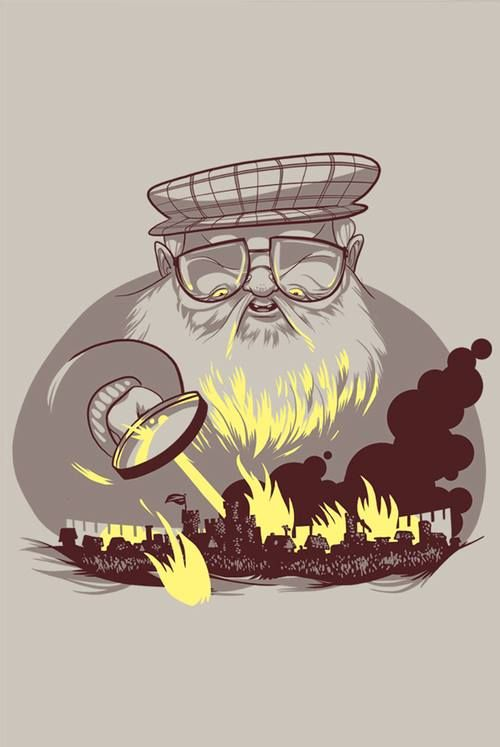

В данном задании вы будете работать с датасетом о персонажах из вселенной Игры Престолов [A Wiki of Ice and Fire](http://awoiaf.westeros.org/). Вам предстоит предсказать, кто из персонажей умрет, а кто останется вживых.



Описание данных:

* **name**: Имя персонажа

* **Title**: Социальный статус или знатность

* **House**: Дом, к которому принадлежит персонаж

* **Culture**: Социальная группа, к которой принадлежит персонаж

* **book1/2/3/4/5**: Появление персонажа в книге

* **Is noble**: Знатность персонажа, основанное на титуле

* **Age**: Отсчет времени: 305 AC

* **male**: Мужчина или женщина

* **dateOfBirth**: дата рождения

* **Spouse**: Имя супруги\а персонажа

* **Father**: Имя отца персонажа

* **Mother**: Имя матери персонажа

* **Heir**: Имя наследника персонажа

* **Is married**: Represents whether the character is married

* **Is spouse alive**: Represents whether character's spouse is alive

* **Is mother alive:** Жива ли мать персонажа

* **Is heir alive:** Жив ли наследник персонажа

* **Is father alive:** Указывает, жив ли отец персонажа

* **Number dead relations:** Количество умерших персонажей, с которыми персонаж связан

* **Popularity score:** Количество внутренних входящих и исходящих ссылок на страницу персонажей в вики http://awoiaf.westeros.org

Целевая переменная:
* **isAlive**: жив ли персонаж в книге

Оценивание:

Баллы считаются следующим образом:

1) $1.00 \geqslant score \geqslant 0.65$ --- 5 баллов

2) $0.65 > score \geqslant 0.50$ --- 4 балла

3) $0.50 > score \geqslant 0.45$ --- 3 балла

4) $0.45 > score \geqslant 0.40$ --- 2 балла

5) $0.40 > score \geqslant 0.35$ --- 1 балл

6) $0.35 > score$ --- 0 баллов

## Часть 1. Анализ и предобработка данных

Здесь вам необходимо сделать все шаги, которые обсуждались в первой части семинара.
* Предобработка данных
  * Обработка пропущенных данных
  * Создание новых признаков
  * Удаление ненужных столбцов
* Анализ данных
  * Анализ целевой переменной
  * Анализ признаков
  * Анализ влияния признаков на целевую переменную
* Подготовка данных для обучения модели

Загружаем датасет

In [1]:
# !gdown 1h99toeF7lZ2I3iJwehgKO-QQmDaOe_O3 # test dataset
# !gdown 1XL0VTygpZj-ZAuTNRBgApZTPQyNDnT-v # train dataset

**Задание 1.1.** Импортируйте библиотеки pandas, matplotlib, seaborn

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

**Задание 1.2.** Загрузите датасет в Pandas DataFrame при помощи функции `read_csv`. Вместо дефолтных наименований строк `0,1,...`, при помощи параметра `index_col`, сделайте значения колонки `S.No` наименованиями строк:

In [3]:
data = pd.read_csv("game_of_thrones_train.csv", index_col="S.No")

Посмотрите, какие типы данных представлены в нашем датасете

Знакомый нам метод describe() возвращает различную информацию для столбцов с числовыми типами данных, и с типами данных *object*

Давайте посмотрим на вывод для типа данных *object*. Для этого:
- сначала применим метод describe(). Укажем в качестве аргумента тип данных столбцов, статистику по которым мы хотим посмотреть (см. https://pandas.pydata.org/docs/reference/api/pandas.Series.map.html)
- для удобства восприятия транспонируем таблицу

In [4]:
data.describe(include="object").T

,count,unique,top,freq
name,1557,1557,Viserys II Targaryen,1
title,717,195,Ser,306
culture,488,51,Northmen,94
mother,18,16,Rhaenyra Targaryen,2
father,22,19,Daemon Targaryen,2
heir,21,20,Jaehaerys Targaryen,2
house,1176,315,House Frey,89
spouse,200,186,Walder Frey,6


Теперь давайте посмотрим на столбцы с числовыми типами данных. Дополните код ниже. Для удобства восприятия мы транспонировали таблицу и ограничили вывод тремя столбцами - количество строк без NaN, максимальное и минимальное значение (о кастомизации вариантах вывода describe() вы можете почитать в документации по ссылке выше).


In [5]:
data.describe(include=None).T[['count', 'min', 'max']]

,count,min,max
male,1557.0,0.0,1.0
dateOfBirth,279.0,-25.0,299.0
book1,1557.0,0.0,1.0
book2,1557.0,0.0,1.0
book3,1557.0,0.0,1.0
book4,1557.0,0.0,1.0
book5,1557.0,0.0,1.0
isAliveMother,18.0,0.0,1.0
isAliveFather,22.0,0.0,1.0
isAliveHeir,21.0,0.0,1.0


Так мы проверим, есть ли в данных неадекватнные значения.   Большинство числовых столбцов - это числа от 0 до 1. Отрицательные значения `dateOfBirth` не являются ошибкой. Значения age и `numDeadRelations` также выглядят адекватными. Можно переходить к дальнейшим шагам анализа (анонс - а в тестовых данных нас будет ждать сюрприз).

**Задание 1.3.** Предобработка (очистка) данных.

В нашем домашнем задании все пропуски в данных (missing values) уже закодированы как NaN. Проанализируйте, в каких колонках и как часто встречаются NaN значения. Далее вам надо будет принять решение, как их обрабатывать.

In [6]:
data.isna().sum(axis=0)

name                   0
title                840
male                   0
culture             1069
dateOfBirth         1278
mother              1539
father              1535
heir                1536
house                381
spouse              1357
book1                  0
book2                  0
book3                  0
book4                  0
book5                  0
isAliveMother       1539
isAliveFather       1535
isAliveHeir         1536
isAliveSpouse       1357
isMarried              0
isNoble                0
age                 1278
numDeadRelations       0
popularity             0
isAlive                0
dtype: int64

В этом задании удалять строки с NaN (dropna) мы не будем по следующим причинам:
- в обучающем датасете много признаков с большим количество пропусков. Если удалять все строки с NaN, то размер выборки сильно уменьшится. Мы потеряем много данных, которые можно было бы использовать для построения более точной модели.
- тестовом датасете также много признаков с NaN (вы можете в этом убедиться, если скачаете датасет и совершите с ним те же действия, что выше проделали с обучаюшим датасетом). Поэтому нам все-равно придется придумать способ кодировать NaN, чтобы модель делала прогнозы для всех персонажей из тестового датасета. Для этого нам потребуется сохранять, а не удалять данные в обучающем датасете.     



Как вы могли заметить, в наших данных очень много пропущенных значений, причём в некоторых случая пропущена **большая** часть значений. Поэтому заполнять по умолчанию медианой/средним/модой в данном случае - не самый лучший способ (однако, это довольно часто используемый метод заполнения, который может пригодиться вам в будущем)

Ниже мы посмотрим, как можно работать с признаками с большим количеством пропущенных значений.

**Задание 1.4.** Числовые признаки

У нас есть **признак popularity**. Постройте гистограмму распределения данного признака с количеством интервалов (bins), равным 50 (https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.hist.html)

<Axes: >

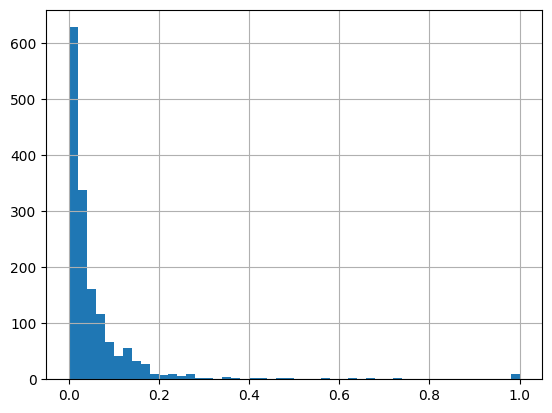

In [7]:
data["popularity"].hist(bins=50)

Распределение сильно несимметрично. Можно преобразовать данный признак, например, по формуле `np.log10(data["popularity"]*M+1)` (добавляем 1 ради логарифма, так как для некоторых персонажей `popularity==0`). В качестве M можно попробовать, например, M=100 или другое число.

При желании для `popularity` вы можете использовать свой способ шкалирования признаков с несимметричным распределением.


<Axes: >

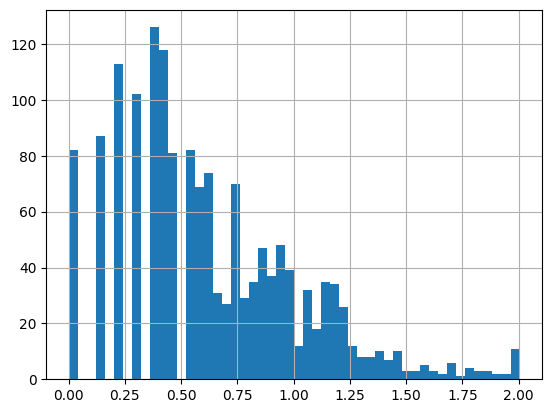

In [8]:
M = 100
data["popularity"] = np.log10(data["popularity"]*M + 1)
data["popularity"].hist(bins=50)

В качестве альтернативного подхода вы можете попробовать дискретизацию признака popularity на основе квантилей (quantile binning), используя функцию qcut() (https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.qcut.html). В этом случае вы преобразуете числовой признак popularity в категориальный, для которого в дальнейшем надо будет применить one-hot кодирование.

Теперь давайте обработаем **признак numDeadRelations**.
Посмотрите на частотное распределение этого признака. Лишь для малого числа персонажей `numDeadRelations>0`.

Создайте признак `boolDeadRelations`. Давайте упростим признак `numDeadRelations`, и просто поделим людей на тех, у кого были хоть какие то отношения с мертвыми персонажами, т.е. `numDeadRelations > 0`, и те, у которых не было, т.е. `numDeadRelations = 0`.

<Axes: >

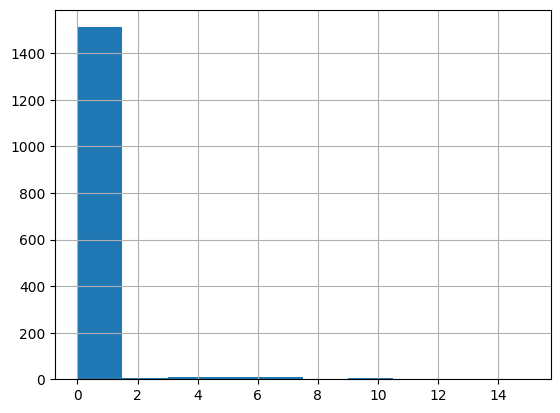

In [9]:
data["numDeadRelations"].hist()

In [10]:
data.loc[(data["numDeadRelations"] == 0), "boolDeadRelations"] = False
data.loc[(data["numDeadRelations"] > 0), "boolDeadRelations"] = True
data.drop(columns=["numDeadRelations"], inplace=True)

Наконец, давайте посмотрим на **признак age**. В нем очень много пропущенных значений. Для того, чтобы использовать в модели информацию о возрасте персонажа, мы создадим два новых признака: `age_value` и `age_no_data`

- Там где возраст указан, `age_value` принимает значение `age`, а `age_no_data` - значение 0.
- Там где возраст не указан, `age_value` принимает значение 0, а `age_no_data` - значение 1.  

Фактически, в переменной `age` мы заменяем NaN на 0, но одновременно добавляем в модель еще один бинарный признак `age_no_data`, несущий информацию о том, у каких персонажей не был указан возраст:        

In [11]:
data["age"].info()

<class 'pandas.core.series.Series'>
Index: 1557 entries, 1 to 1557
Series name: age
Non-Null Count  Dtype  
--------------  -----  
279 non-null    float64
dtypes: float64(1)
memory usage: 24.3 KB


In [12]:
data["age_value"] = [x if not np.isnan(x) else 0 for x in data["age"]]
data["age_no_data"] = [1 if np.isnan(x) else 0 for x in data["age"]]
data.drop(columns=["age"], inplace=True)

Этот способ чем-то похож на работу с категориальной переменными с пропущенными значениями, когда мы добавляем еще одну категорию no_data и заменяем NaN на значение этой категории.

Если вы заходите похожим образом образом обработать признак `dateOfBirth`, **обратите внимание**, что у одних и тех же персонажей не указан и возраст, и год рождения.
То есть созданные признаки `age_no_data` и `dateOfBirth_no_data` будут полностью совпадать, и в модель надо будет включать только один из признаков: или `age_no_data`, или `dateOfBirth_no_data`.

<class 'pandas.core.series.Series'>
Index: 1557 entries, 1 to 1557
Series name: dateOfBirth
Non-Null Count  Dtype  
--------------  -----  
279 non-null    float64
dtypes: float64(1)
memory usage: 24.3 KB


None

<Axes: >

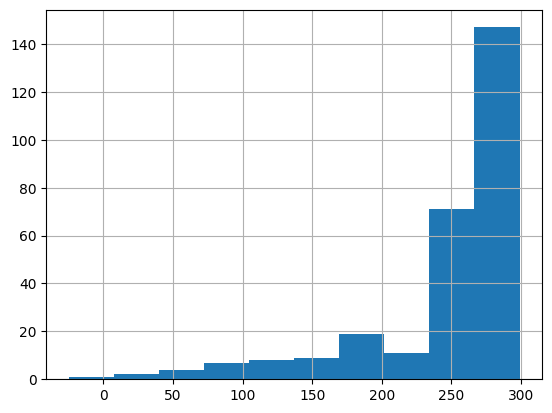

In [13]:
display(data["dateOfBirth"].info())
data["dateOfBirth"].hist()
# Признак использовать не будем в силу наличия признака age

**Задание 1.5.** Категориальные признаки с большим количеством категорий

**Признак culture** содержит информацию о принадлежности к одному из народов во вселенной Игры Престолов.

Давайте посмотрим, какие значения принимает данный признак. По умолчанию метод `value_counts()` игнорирует пропуски в данных, поэтому используем этот метод с параметром **dropna** со значением **False** (см. https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.value_counts.html)

In [14]:
data['culture'].value_counts(dropna=False)

culture
NaN                        1069
Northmen                     94
Ironborn                     91
Free Folk                    45
Braavosi                     39
Valyrian                     28
Ghiscari                     17
Dornish                      17
Dothraki                     17
Reach                        13
Vale mountain clans          12
Rivermen                     10
Valemen                      10
northmen                      9
Westerman                     8
Free folk                     7
Tyroshi                       6
Qartheen                      5
Stormlands                    4
Summer Isles                  4
Astapori                      4
Westeros                      3
Dornishmen                    3
Ironmen                       3
Northern mountain clans       3
Westermen                     3
Lysene                        2
westermen                     2
Meereenese                    2
Myrish                        2
Crannogmen                    2


Из полученного частотного распределения видно, что для большого числа персонажей значения данного признака не указаны. Также есть много редких значений признака, которые в выборке повторяются один или несколько раз. Причина отчасти в том, что один и тот же народ упоминается в нашем датасете под разными названиями.

Данную проблему мы попытаемся решить, сгруппировав народы в более крупные категории. Так мы одновременно решим проблему того, что один и тот же народ назван в выборке разными способами.

Предложенный вариант группировки имеет определенную логику. Выделяются следующие группы:
- старые нации, которые уже не существовали как отдельные народы на момент повествования основной линии повествования романов, но отдельные потомки могли еще быть живы
- народы, проживающие в королевствах континента Весторос (для каждого королевства - своя группа)
- народы континента Эссос
- прочие народы

In [15]:
cultures_grouped = {
    'Old Nations': ['valyrian', 'first men', 'andal', 'andals', 'rhoynar'],
    'the North': ['northmen', 'northern mountain clans', 'crannogmen'],
    'the Iron Islands': ['ironborn', 'ironborn', 'ironmen'],
    'the Mountain and the Vale': ['valemen', 'vale', 'vale mountain clans',
                              'sistermen'],
    'the Isles and Rivers': ['riverlands', 'rivermen'],
    'the Rock': ['westerman', 'westermen', 'westerlands'],
    'the Stormlands': ['stormlander', 'stormlands'],
    'the Reach': ['reach', 'reachmen', 'the reach'],
    'Dorne': ['dornish', 'dornishmen', 'dorne'],
    'Essos Nations': ['astapor', 'astapori', 'braavosi', 'braavos', 'tyroshi', 'lysene', 'lyseni',
                      'myrish', 'pentoshi', 'qartheen', 'qarth', 'dothraki',
                      'lhazarene', 'lhazareen','meereen', 'meereenese',
                      'norvoshi', 'qohor', 'summer isles', 'summer islands',
                      'summer islander', 'asshai', "asshai'i", 'norvos', 'ghiscari',
                      'ghiscaricari'],
    'Other Nations': ['ibbenese', 'westeros', 'free folk', 'wildling', 'wildlings', 'naathi']}

**Обратите внимание, что некоторые варианты названий народов встречаются только в тестовых данных, и не встречаются в обучающих данных.** Такая ситуация нередко случается на практике. Поэтому, после обработки обучающих данных и обучения модели важно задать для модели правило, как она должна обрабатывать "незнакомые" категории в категориальных признаках. Например, можно относить объекты с "незнакомой" категорией к некоторой существующей категории или указать формулу расчета для "незнакомой" категории.     

Предложенный вам словарь `cultures_grouped` составлен по всем значениям признака `culture`, встречающимся в тренировочном либо в тестовом датасете. Здесь важно, что все укрупненные категории (ключи/keys словаря `cultures_grouped`) представлены в обоих датасетах, а уникальные для тестового датасета названия народов - это отдельные названия народов внутри укрупненных категорий (значения/values словаря). Поэтому, когда вы будете работать с тестовыми - просто применяйте этот словарь без указания правила обработки "незнакомых" категорий.

Давайте приступим к кодировке значений признака culture.
Для этого сначала инвертируем словарь *cultures_grouped*

In [16]:
#Довольно просто инвертировать словарь, где ключу соответствует одно значение
#В нашем случае ключу соответствует список значений.
#Ниже показан пример, как можно инвертировать такой словарь

d = {'A': ['a1', 'a2', 'a3'],
     'B': ['b1', 'b2', 'b3', 'b4']}

d_inverted = {}
for k in d.keys():
  for v in d[k]:
      d_inverted.update({v:k})

d_inverted

{'a1': 'A', 'a2': 'A', 'a3': 'A', 'b1': 'B', 'b2': 'B', 'b3': 'B', 'b4': 'B'}

In [17]:
# По аналогии с примером выше инвертируйте словарь cultures_grouped
cultures_grouped_inverted = {item: k for k, v in cultures_grouped.items() for item in v}

Теперь создадим новый столбец с укрупненными значениями culture.

Для этого будем использовать метод `map()` с инвертированным словарем в качестве аргумента (https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.map.html)

Обратите внимание, что в словаре названия народов указаны в нижнем регистре. А в датасете используется как нижний, так и верхний регистр. Поэтому перед применением метода `map()` переведем значения столбца culture в нижний регистр при помощи метода `str.lower()` (https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.str.lower.html).

In [18]:
data['culture_grouped'] = data['culture'].str.lower().map(cultures_grouped_inverted)

Осталось заменить все NaN в созданном столбце на категорию `culture_no_data`:

In [19]:
data["culture_grouped"] = data["culture_grouped"].fillna("culture_no_data")
data.drop(columns=["culture"], inplace=True)

In [20]:
data["culture_grouped"].value_counts()

culture_grouped
culture_no_data              1069
Essos Nations                 109
the North                     108
the Iron Islands               95
Other Nations                  57
Old Nations                    32
the Mountain and the Vale      25
Dorne                          21
the Rock                       14
the Reach                      13
the Isles and Rivers           10
the Stormlands                  4
Name: count, dtype: int64

Распределение сгруппированной переменной выглядит гораздо лучше. Но по прежнему есть несколько слабо представленых групп.

Дальнейшую работу с этим признаком проводите на свое усмотрение для повышения качества прогноза модели. Например, можно объединить несколько слабо представленных категорий в одну или применить другой подход.

In [21]:
# Объединим малые группы в общую категорию
vc = data["culture_grouped"].value_counts()
small_nations = vc[vc < 30]
small_nations = {k: "Small Nations" for k in small_nations.index}
small_nations

{'the Mountain and the Vale': 'Small Nations',
 'Dorne': 'Small Nations',
 'the Rock': 'Small Nations',
 'the Reach': 'Small Nations',
 'the Isles and Rivers': 'Small Nations',
 'the Stormlands': 'Small Nations'}

In [22]:
data['culture_grouped'] = data['culture_grouped'].replace(small_nations)

In [23]:
data["culture_grouped"].value_counts()

culture_grouped
culture_no_data     1069
Essos Nations        109
the North            108
the Iron Islands      95
Small Nations         87
Other Nations         57
Old Nations           32
Name: count, dtype: int64

**Задание 1.6.** Категориальные признаки в линейных моделях

Для включения категориальных признаков в линейную модель их нужно преобразовать в числовые признаки.

Если признак принимает одно из двух возможных значений (например, персонаж "появляется" или "не появляется" в 1-й книге), он напрямую кодируется в бинарный признак ("появляется" -> 1, "не появляется" -> 0). Если признак принимает больше двух значений, его можно преобразовать в несколько бинарных при помощи one-hot преобразования. В некоторых случаях бывает полезно объединить некоторые категории, как мы это поступили с признаком *culture*.

Порядковых признаков у нас в задаче нет, поэтому рассматривать их здесь мы не будем.

Для того, чтобы найти все порядковые признаки, посмотрим на количество уникальных значений, которые встречаются в столбцах. Для столбцов с типом object количество уникальных значений мы выводили  при помощи метода `describe()` в задании 1.2.

Чтобы посмотреть количество уникальных значений для всех столбцов, можно воспользоваться методом nunique() (https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.nunique.html)

In [24]:
# Количество уникальных значений в каждом столбце
data.nunique()

name                 1557
title                 195
male                    2
dateOfBirth           105
mother                 16
father                 19
heir                   20
house                 315
spouse                186
book1                   2
book2                   2
book3                   2
book4                   2
book5                   2
isAliveMother           2
isAliveFather           2
isAliveHeir             2
isAliveSpouse           2
isMarried               2
isNoble                 2
popularity            117
isAlive                 2
boolDeadRelations       2
age_value              72
age_no_data             2
culture_grouped         7
dtype: int64

In [25]:
# Для числовых столбцов можно вывести в одну таблицу более детальную статистику, объединив выводы describe() и nunique()
# Код ниже требуется дополнить по аналогии с заданием 1.2.
data.describe(include=None).T[['count', 'min', 'max']].assign(N_unique_values = data.nunique())

,count,min,max,N_unique_values
male,1557.0,0.0,1.000000,2
dateOfBirth,279.0,-25.0,299.000000,105
book1,1557.0,0.0,1.000000,2
book2,1557.0,0.0,1.000000,2
book3,1557.0,0.0,1.000000,2
book4,1557.0,0.0,1.000000,2
book5,1557.0,0.0,1.000000,2
isAliveMother,18.0,0.0,1.000000,2
isAliveFather,22.0,0.0,1.000000,2
isAliveHeir,21.0,0.0,1.000000,2


Посмотрев на количество уникальных значений мы можем выделить категориальные признаки. Например, `popularity` принимает значения от 0 до 1, но это непрерывный числовой признак. Остальные признаки со значениями от 0 до 1 - принимают только два значения, то есть являются бинарными.

Бинарные признаки без NaN полностью готовы для включения в модель. Некоторые бинарные признаки содержат пропуски, поэтому, если вы захотите включить их в модель, их потребуется обработать.

Для бинарных признаков их связь с зависимой переменной можно прикинуть по таблице корреляций. Для категориальных признаков с количеством значений больше двух (или с двумя значениями и NaN) можно сделать one-hot преобразования и посчитать корреряцию зависимой переменной с набором сгенерированных бинарных признаков.
В качестве альтернативного подхода можно использовать сравнение средних значений зависимой переменной для разных категорий исследуемого признака. Чем сильнее различаются средние значения целевой переменной между категориями, тем вероятнее, что данный признак связан с зависимой переменной.

In [26]:
# попробуйте провести сравнение средних зависимой пременной isAlive для признака isAliveSpouse
# одним из приведенных ниже способов:

display(data.groupby('isAliveSpouse', dropna = False)['isAlive'].mean())
display(pd.pivot_table(data = data, values = 'isAlive', index = 'isAliveSpouse', aggfunc=['mean', 'count'], dropna=False))

isAliveSpouse
0.0    0.619048
1.0    0.753165
NaN    0.786293
Name: isAlive, dtype: float64

,mean,count
,isAlive,isAlive
isAliveSpouse,,
0.0,0.619048,42
1.0,0.753165,158
NaN,0.786293,1357


**Задание 1.7.** Проанализируйте признаки.
  * Обработайте категориальные признаки и переведите их в числа. Можете выбрать любой кодировщик. Не забудьте, что потом аналогичным образом вам надо будет преобразовывать тестовый датасет, используя тот же алгоритм кодирования признаков.
  * Проанализируйте количественные признаки. Есть ли корреляция между признаками?

In [27]:
display(data.columns)
categorical_features = {
    "name",
    "title",
    "male",
    "mother",
    "father",
    "heir",
    "house",
    "spouse",
    "book1",
    "book2",
    "book3",
    "book4",
    "book5",
    "isAliveMother",
    "isAliveFather",
    "isAliveHeir",
    "isAliveSpouse",
    "isMarried",
    "isNoble",
    "boolDeadRelations",
    "age_no_data",
    "culture_grouped",
}
numerical_features = {"dateOfBirth", "popularity", "age_value"}
target = {"isAlive"}

Index(['name', 'title', 'male', 'dateOfBirth', 'mother', 'father', 'heir',
       'house', 'spouse', 'book1', 'book2', 'book3', 'book4', 'book5',
       'isAliveMother', 'isAliveFather', 'isAliveHeir', 'isAliveSpouse',
       'isMarried', 'isNoble', 'popularity', 'isAlive', 'boolDeadRelations',
       'age_value', 'age_no_data', 'culture_grouped'],
      dtype='object')

In [28]:
# Проверяем, что признаки не потеряны
set(data.columns) == categorical_features | numerical_features | target

True

In [29]:
data.describe(include="object").T

,count,unique,top,freq
name,1557,1557,Viserys II Targaryen,1
title,717,195,Ser,306
mother,18,16,Rhaenyra Targaryen,2
father,22,19,Daemon Targaryen,2
heir,21,20,Jaehaerys Targaryen,2
house,1176,315,House Frey,89
spouse,200,186,Walder Frey,6
boolDeadRelations,1557,2,False,1488
culture_grouped,1557,7,culture_no_data,1069


In [30]:
unprocessed_categorical_features = set(data[list(categorical_features)].select_dtypes(include="object").columns.to_list())
unprocessed_categorical_features -= {"name", "mother", "father", "heir", "spouse", "boolDeadRelations"}
unprocessed_categorical_features = list(unprocessed_categorical_features)
unprocessed_categorical_features

['culture_grouped', 'title', 'house']

In [31]:
from sklearn.preprocessing import OneHotEncoder

one_hot_encoder = OneHotEncoder(sparse_output=False, handle_unknown='infrequent_if_exist')
one_hot_encoded = one_hot_encoder.fit_transform(data[unprocessed_categorical_features].values)
one_hot_df = pd.DataFrame(one_hot_encoded, columns=one_hot_encoder.get_feature_names_out(unprocessed_categorical_features), index=data.index)

In [32]:
data_encoded = pd.concat([data, one_hot_df], axis=1)
data_encoded = data_encoded.drop(unprocessed_categorical_features, axis=1)
data_encoded.head()

,name,male,dateOfBirth,mother,father,heir,spouse,book1,book2,book3,...,house_Sea watch,house_Second Sons,house_Stone Crows,house_Stormcrows,house_Summer Islands,house_The Citadel,house_Windblown,house_Wise Masters,house_wildling,house_nan
S.No,,,,,,,,,,,,,,,,,,,,,
1,Viserys II Targaryen,1,NaN,Rhaenyra Targaryen,Daemon Targaryen,Aegon IV Targaryen,NaN,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,Walder Frey,1,208.0,NaN,NaN,NaN,Perra Royce,1,1,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,Addison Hill,1,NaN,NaN,NaN,NaN,NaN,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Aemma Arryn,0,82.0,NaN,NaN,NaN,Viserys I Targaryen,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,Sylva Santagar,0,276.0,NaN,NaN,NaN,Eldon Estermont,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


<Axes: >

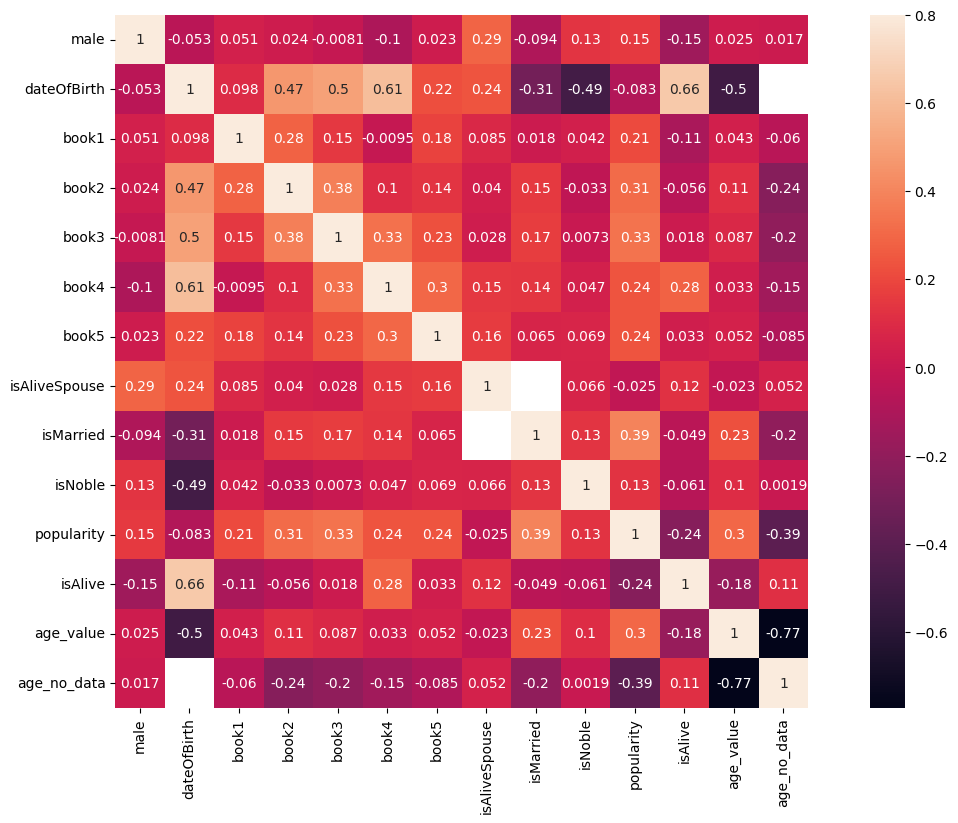

In [33]:
corrmat = data.select_dtypes(exclude="object").drop(columns=["isAliveMother", "isAliveFather", "isAliveHeir"]).corr()
fig, ax = plt.subplots(figsize=(16, 9))
sns.heatmap(corrmat, vmax=0.8, square=True, annot=True)

**Задание 1.8.** Проанализируйте влияние признаков на целевую переменную.

In [34]:
corrmat["isAlive"].sort_values(ascending=False)

isAlive          1.000000
dateOfBirth      0.655881
book4            0.284014
isAliveSpouse    0.122341
age_no_data      0.113629
book5            0.032531
book3            0.018427
isMarried       -0.049381
book2           -0.055998
isNoble         -0.060572
book1           -0.112468
male            -0.148290
age_value       -0.181938
popularity      -0.242497
Name: isAlive, dtype: float64

**Задание 1.9.** Создайте переменные `X`, которая будет хранить только значения признаков, которые вы отобрали для включения в модель, и `y`, которая будет хранить только значения целевой переменной.

In [35]:
numerical_features, categorical_features

({'age_value', 'dateOfBirth', 'popularity'},
 {'age_no_data',
  'book1',
  'book2',
  'book3',
  'book4',
  'book5',
  'boolDeadRelations',
  'culture_grouped',
  'father',
  'heir',
  'house',
  'isAliveFather',
  'isAliveHeir',
  'isAliveMother',
  'isAliveSpouse',
  'isMarried',
  'isNoble',
  'male',
  'mother',
  'name',
  'spouse',
  'title'})

In [36]:
numerical_features = numerical_features - {"dateOfBirth"}
categorical_features = (
    categorical_features
    - {"name", "mother", "father", "heir", "spouse", "isAliveFather", "isAliveHeir", "isAliveMother", "isAliveSpouse"}
    - set(unprocessed_categorical_features)
)
categorical_features = categorical_features | set(one_hot_df.columns)
model_features = list(numerical_features) + list(categorical_features)

In [37]:
data_encoded[model_features].describe().T

,count,mean,std,min,25%,50%,75%,max
popularity,1557.0,0.621287,0.402654,0.0,0.368806,0.523894,0.866554,2.004321
age_value,1557.0,6.323699,17.535217,0.0,0.000000,0.000000,0.000000,100.000000
title_Magister of Pentos,1557.0,0.000642,0.025343,0.0,0.000000,0.000000,0.000000,1.000000
title_Lord of Greyshield,1557.0,0.000642,0.025343,0.0,0.000000,0.000000,0.000000,1.000000
house_House Staedmon,1557.0,0.000642,0.025343,0.0,0.000000,0.000000,0.000000,1.000000
...,...,...,...,...,...,...,...,...
house_House Sharp,1557.0,0.001927,0.043867,0.0,0.000000,0.000000,0.000000,1.000000
house_House Bracken,1557.0,0.005780,0.075833,0.0,0.000000,0.000000,0.000000,1.000000
house_Black Ears,1557.0,0.000642,0.025343,0.0,0.000000,0.000000,0.000000,1.000000
title_Lord of Kingsgrave,1557.0,0.000642,0.025343,0.0,0.000000,0.000000,0.000000,1.000000


In [38]:
X = data_encoded[model_features].to_numpy()
y = data_encoded["isAlive"].to_numpy()

**Задание 1.10.** Разделите датасет обучащую и валидационные части (train и val) при помощи функции `train_test_split` (https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html)

In [39]:
from sklearn.model_selection import train_test_split

In [40]:
# не забудьте в функции train_test_split задать параметр random_state,
# чтобы обеспечить повторяемость разбиения выборки на train и validation части.
# Это позволит сравнивать метрики моделей с различными методами подготовки признаков
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, shuffle=True, random_state=42)
X_train.shape, y_train.shape, X_val.shape, y_val.shape

((1245, 531), (1245,), (312, 531), (312,))

## Часть 2. Обучение моделей

В данной части домашнего задания, мы хотим научиться обучать модели для задачи классификации на наших данных.

**Задание 2.1.**


Вы можете работать с одной из предложенных моделей из библиотеки `sklearn`
* LogisticRegression
* RandomForestClassifier
* AdaBoostClassifier
* GaussianProcessClassifier
* GaussianNB
* KNeighborsClassifier
* SVC
* DecisionTreeClassifier


Однако в этом домашнем задании мы предлагаем выбрать и поработать с моделью `LogisticRegression`.

In [41]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

Импортируйте остальные модели из библиотеки `sklearn`. Чтобы понять как это сделать, воспользуйтесь официальный документацией `sklearn` $→$ [тык](https://scikit-learn.org/dev/user_guide.html). По ключевому названию модели, вы сможете найти необходимую информацию о том, как можно импортировать модель из библиотеки.

**Задание 2.2.** Обучите модель и сделайте предсказание на тестовой выборке

В качестве примера, обучим модель `LogisticRegression` и сделаем на ней предсказания на тестовой выборке.

In [42]:
def train_and_predict(X_train, y_train, X_val, classifier, **kwargs):
    # Шаг 1. создание модели
    model = classifier(**kwargs)

    # Шаг 2. обучение модели
    model.fit(X_train, y_train)

    # Шаг 3. Предсказание на тестовых данных
    y_pred = model.predict(X_val)

    return y_pred

## Часть 3. Оцените качество моделей

Вам необходимо познакомиться с метриками задачи классификации из sklearn. Оцените все модели и выберите лучшую по метрике качества Accuracy.

С метриками классификации вы можете ознакомиться в [Yandex ML Book](https://education.yandex.ru/handbook/ml/article/metriki-klassifikacii-i-regressii).

Для простоты в данном домашнем задании мы будем работать с самой базовой метрикой для задачи классификации - accuracy.

**Задание 3.1.** Вам необходимо посчитать метрику для всех моделей и выбрать лучшую модель.

Сначала импортируем необходимую функцию из библиотеки sklearn для подсчета accuracy.

In [43]:
from sklearn.metrics import accuracy_score

В качестве примера, посчитаем метрику accuracy для модели `LogisticRegression`

In [44]:
# Шаг 3. Предсказание на тестовых данных

y_pred = train_and_predict(X_train=X_train, y_train=y_train, X_val=X_val, classifier=LogisticRegression, max_iter=1000)

# Шаг 4. Оценка предсказания по метрике accuracy
accuracy = accuracy_score(y_val, y_pred)
print("Accuracy : %.4f" % accuracy)

Accuracy : 0.8013


Возможно, вы решите вернуться на несколько шагов и попробовать другие варианты преобразования и подбора признаков в модель. **Выберите** лучшую модель.

In [45]:
classifiers = {
    LogisticRegression: {"max_iter": 1000},
    RandomForestClassifier: {},
    AdaBoostClassifier: {},
    GaussianProcessClassifier: {},
    GaussianNB: {},
    KNeighborsClassifier: {},
    SVC: {},
    DecisionTreeClassifier: {},
}

In [46]:
for clsf, kwargs in classifiers.items():
    y_pred = train_and_predict(X_train=X_train, y_train=y_train, X_val=X_val, classifier=clsf, **kwargs)
    accuracy = accuracy_score(y_val, y_pred)
    print(f"Classifier: {clsf}, Accuracy: {accuracy:.4f}")

Classifier: <class 'sklearn.linear_model._logistic.LogisticRegression'>, Accuracy: 0.8013
Classifier: <class 'sklearn.ensemble._forest.RandomForestClassifier'>, Accuracy: 0.8205
Classifier: <class 'sklearn.ensemble._weight_boosting.AdaBoostClassifier'>, Accuracy: 0.7917
Classifier: <class 'sklearn.gaussian_process._gpc.GaussianProcessClassifier'>, Accuracy: 0.7788
Classifier: <class 'sklearn.naive_bayes.GaussianNB'>, Accuracy: 0.4167
Classifier: <class 'sklearn.neighbors._classification.KNeighborsClassifier'>, Accuracy: 0.7885
Classifier: <class 'sklearn.svm._classes.SVC'>, Accuracy: 0.7660
Classifier: <class 'sklearn.tree._classes.DecisionTreeClassifier'>, Accuracy: 0.8013


### Тестовый датасет

В самом начале нашего домашнего задания мы скачивали тестовый датасет. Загрузите его в Pandas DataFrame при помощи функции read_csv

In [47]:
data_test = pd.read_csv("game_of_thrones_test.csv", index_col="S.No")

По аналогии с тем, как мы работали с обучающим датасетом, давайте посмотрим в тестовом датасете на статистики признаков с разными типами данных  

In [48]:
#Подсказка
data_test.loc[data_test['age'] < 0] # Находим данные с ошибками в дате рождения и возрасте

,name,title,male,culture,dateOfBirth,mother,father,heir,house,spouse,...,book5,isAliveMother,isAliveFather,isAliveHeir,isAliveSpouse,isMarried,isNoble,age,numDeadRelations,popularity
S.No,,,,,,,,,,,,,,,,,,,,,
1685,Doreah,NaN,0,Lysene,278279.0,NaN,NaN,NaN,House Targaryen,NaN,...,1,NaN,NaN,NaN,NaN,0,0,-277980.0,0,0.110368
1869,Rhaego,NaN,0,NaN,298299.0,NaN,NaN,NaN,House Targaryen,NaN,...,0,NaN,NaN,NaN,NaN,0,0,-298001.0,6,0.167224


In [49]:
#Вы можете аккуратно поправить тестовые данные, воспользовавшись, например следующим кодом:
data_test.loc[1685, 'dateOfBirth'] = 278.
data_test.loc[1869, 'dateOfBirth'] = 299.
# замены в строке 1685: dateOfBirth -> 278. и age -> 0.
# замены в строке 1869: dateOfBirth -> 299. и age -> 0.

Преобразуйте признаки в тестовом датасете по тому же пайплайну, как вы преобразовывали обучающие данные. Примените вашу лучшую модель на тестовом датасете для получения прогноза целевой переменной `isAlive`

In [50]:
data_test["popularity"] = np.log10(data_test["popularity"]*M + 1)

In [51]:
data_test.loc[(data_test["numDeadRelations"] == 0), "boolDeadRelations"] = False
data_test.loc[(data_test["numDeadRelations"] > 0), "boolDeadRelations"] = True
data_test.drop(columns=["numDeadRelations"], inplace=True)

In [52]:
data_test["age_value"] = [x if not np.isnan(x) else 0 for x in data_test["age"]]
data_test["age_no_data"] = [1 if np.isnan(x) else 0 for x in data_test["age"]]
data_test.drop(columns=["age"], inplace=True)

In [53]:
data_test["culture_grouped"] = data_test["culture"].str.lower().map(cultures_grouped_inverted)
data_test["culture_grouped"] = data_test["culture_grouped"].fillna("culture_no_data")
data_test.drop(columns=["culture"], inplace=True)

In [54]:
data_test["culture_grouped"] = data_test["culture_grouped"].replace(small_nations)

In [55]:
data_test.describe(include="object").T

,count,unique,top,freq
name,389,389,Melissa Blackwood,1
title,221,109,Ser,78
mother,3,3,Dyanna Dayne,1
father,4,4,Maekar I Targaryen,1
heir,2,2,Duncan Targaryen,1
house,343,137,House Targaryen,22
spouse,76,75,Tyrion Lannister,2
boolDeadRelations,389,2,False,313
culture_grouped,389,7,culture_no_data,200


In [56]:
unprocessed_categorical_features

['culture_grouped', 'title', 'house']

In [57]:
one_hot_encoded_test = one_hot_encoder.transform(data_test[unprocessed_categorical_features].values)
one_hot_df_test = pd.DataFrame(
    one_hot_encoded_test, columns=one_hot_encoder.get_feature_names_out(unprocessed_categorical_features), index=data_test.index
)

In [58]:
data_test_encoded = pd.concat([data_test, one_hot_df_test], axis=1)
data_test_encoded = data_test_encoded.drop(unprocessed_categorical_features, axis=1)
data_test_encoded.head()

,name,male,dateOfBirth,mother,father,heir,spouse,book1,book2,book3,...,house_Sea watch,house_Second Sons,house_Stone Crows,house_Stormcrows,house_Summer Islands,house_The Citadel,house_Windblown,house_Wise Masters,house_wildling,house_nan
S.No,,,,,,,,,,,,,,,,,,,,,
1558,Melissa Blackwood,0,156.0,NaN,NaN,NaN,NaN,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1559,Melisandre,0,NaN,NaN,NaN,NaN,NaN,0,1,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1560,Merrit,0,NaN,NaN,NaN,NaN,NaN,0,0,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1561,Meryn Trant,1,NaN,NaN,NaN,NaN,NaN,1,1,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1562,Merrett Frey,1,262.0,NaN,NaN,NaN,Mariya Darry,1,1,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [59]:
data_test_encoded[model_features]

,popularity,age_value,title_Magister of Pentos,title_Lord of Greyshield,house_House Staedmon,house_House Farwynd of the Lonely Light,house_House Hogg,house_House Ambrose,house_Sea watch,age_no_data,...,house_House Wull,title_Blackcrown,title_Heart's Home,house_House Pemford,house_House Piper,house_House Sharp,house_House Bracken,house_Black Ears,title_Lord of Kingsgrave,house_House Jast
S.No,,,,,,,,,,,,,,,,,,,,,
1558,0.779360,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1559,1.878418,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1560,0.301756,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1561,1.363115,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1562,1.648148,38.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1942,1.557712,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1943,1.029343,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1944,0.603148,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [60]:
X_test = data_test_encoded[model_features].to_numpy()

In [61]:
# Обучение и предсказание лучшей модели
model = RandomForestClassifier()
model.fit(X_train, y_train)
y_pred_test = model.predict(X_test)

### Файл `submission.csv`

Вам нужно вместо значений в `submission.csv` файле в колонке `isAlive`, подставить свои предсказания и сохранить измененный файл.

In [62]:
# !gdown 1M14conWjAW2QLoyCXbHEAy8bql2f99eF

In [63]:
submission = pd.read_csv("submission.csv", index_col='S.No')

In [64]:
submission["isAlive"] = y_pred_test
submission

,isAlive
S.No,
1558,0
1559,1
1560,1
1561,1
1562,1
...,...
1942,1
1943,1
1944,1


Как сохранить измененный Pandas DataFrame в csv файл:

In [65]:
submission.to_csv("new_submission.csv", index=False)